In [1]:
from sklearn.datasets import fetch_20newsgroups
import numpy as np 

In [2]:
cats = ['sci.space', 'soc.religion.christian', 'talk.politics.guns']

In [3]:
dataset = fetch_20newsgroups(
    remove=("headers", "footers", "quotes"),
    subset="all",
    categories=cats,
    shuffle=True, 
    random_state=42
)

In [4]:
labels = dataset.target
unqiue_labels, category_size = np.unique(labels, return_counts=True)
true_k = unqiue_labels.shape[0]
print(f"{len(dataset.data)} documents - {true_k} categories")

2894 documents - 3 categories


In [5]:
?collections.defaultdict

Init signature: collections.defaultdict(self, /, *args, **kwargs)
Docstring:     
defaultdict(default_factory=None, /, [...]) --> dict with default factory

The default factory is called without arguments to produce
a new value when a key is not present, in __getitem__ only.
A defaultdict compares equal to a dict with the same items.
All remaining arguments are treated the same as if they were
passed to the dict constructor, including keyword arguments.
File:           ~/anaconda3/lib/python3.13/collections/__init__.py
Type:           type
Subclasses:     FreezableDefaultDict

In [6]:
?time.time

Object `time.time` not found.


In [7]:
from collections import defaultdict
from time import time

from sklearn import metrics

evaluations = []
evaluations_std = []

def fit_and_evaluate(km, X, name=None, n_nums=5):
    name = km.__class__.__name__ if name is None else name
    train_times = []
    scores = defaultdict(list)

    for seed in range(n_nums): 
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)

        train_times.append(time() - t0) 
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(metrics.adjusted_rand_score(labels, km.labels_))
        scores["Silhouette Coefficient"].append(metrics.silhouette_score(X, km.labels_, sample_size=2000))

    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name, 
        "train_time": train_times.std(), 
    }
    evaluation_std = {
        "estimator": name, 
        "train_time": train_times.std(), 
    }

    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)
    
        
        

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_df=0.5,
    min_df=5,
    stop_words="english",
)
t0 = time()
X_tfidf = vectorizer.fit_transform(dataset.data)

print(f"vectorization done in {time() - t0:.3f} s")
print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

vectorization done in 0.322 s
n_samples: 2894, n_features: 7429


In [9]:
print(f"{X_tfidf.nnz / np.prod(X_tfidf.shape):.3f}")

0.008


In [10]:
from sklearn.cluster import KMeans

for seed in range(5):
    kmeans = KMeans(
        n_clusters=true_k,
        max_iter=100,
        n_init=1,
        random_state=seed,
    ).fit(X_tfidf)
    cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
    print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print()
print(
    "True number of documents in each category according to the class labels: "
    f"{category_size}"
)

Number of elements assigned to each cluster: [1677  649  568]
Number of elements assigned to each cluster: [   3 2890    1]
Number of elements assigned to each cluster: [   1 2892    1]
Number of elements assigned to each cluster: [ 483  578 1833]
Number of elements assigned to each cluster: [ 398 1918  578]

True number of documents in each category according to the class labels: [987 997 910]


In [11]:
kmeans = KMeans(
    n_clusters=true_k,
    max_iter=100,
    n_init=5,
)

fit_and_evaluate(kmeans, X_tfidf, name="KMeans\non tf-idf vectors")

clustering done in 0.07 ± 0.01 s 
Homogeneity: 0.389 ± 0.033
Completeness: 0.461 ± 0.025
V-measure: 0.422 ± 0.030
Adjusted Rand-Index: 0.286 ± 0.052
Silhouette Coefficient: 0.009 ± 0.000


In [12]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

lsa = make_pipeline(TruncatedSVD(n_components=100), Normalizer(copy=False))
t0 = time()
X_lsa = lsa.fit_transform(X_tfidf)
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"LSA done in {time() - t0:.3f} s")
print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

LSA done in 0.324 s
Explained variance of the SVD step: 18.6%


In [13]:
kmeans = KMeans(
    n_clusters=true_k,
    max_iter=100,
    n_init=1,
)

fit_and_evaluate(kmeans, X_lsa, name="KMeans\nwith LSA on tf-idf vectors")

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.512 ± 0.100
Completeness: 0.562 ± 0.045
V-measure: 0.534 ± 0.079
Adjusted Rand-Index: 0.492 ± 0.132
Silhouette Coefficient: 0.033 ± 0.002


In [14]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(
    n_clusters=true_k,
    n_init=1,
    init_size=1000,
    batch_size=1000,
)

fit_and_evaluate(
    minibatch_kmeans,
    X_lsa,
    name="MiniBatchKMeans\nwith LSA on tf-idf vectors",
)

clustering done in 0.02 ± 0.01 s 
Homogeneity: 0.322 ± 0.188
Completeness: 0.350 ± 0.183
V-measure: 0.331 ± 0.192
Adjusted Rand-Index: 0.307 ± 0.200
Silhouette Coefficient: 0.022 ± 0.009


In [15]:
original_space_centroids = lsa[0].inverse_transform(kmeans.cluster_centers_)
order_centroids = original_space_centroids.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

for i in range(true_k):
    print(f"Cluster {i}: ", end="")
    for ind in order_centroids[i, :10]:
        print(f"{terms[ind]} ", end="")
    print()

Cluster 0: god jesus church christ christian christians people believe bible faith 
Cluster 1: space like just know don think nasa time orbit launch 
Cluster 2: gun people fbi guns government don batf right just law 


In [16]:
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer

lsa_vectorizer = make_pipeline(
    HashingVectorizer(stop_words="english", n_features=50_000),
    TfidfTransformer(),
    TruncatedSVD(n_components=100, random_state=0),
    Normalizer(copy=False),
)

t0 = time()
X_hashed_lsa = lsa_vectorizer.fit_transform(dataset.data)
print(f"vectorization done in {time() - t0:.3f} s")

vectorization done in 2.181 s


In [17]:
fit_and_evaluate(kmeans, X_hashed_lsa, name="KMeans\nwith LSA on hashed vectors")

clustering done in 0.01 ± 0.00 s 
Homogeneity: 0.487 ± 0.112
Completeness: 0.550 ± 0.054
V-measure: 0.514 ± 0.089
Adjusted Rand-Index: 0.466 ± 0.160
Silhouette Coefficient: 0.031 ± 0.002


In [18]:
fit_and_evaluate(
    minibatch_kmeans,
    X_hashed_lsa,
    name="MiniBatchKMeans\nwith LSA on hashed vectors",
)

clustering done in 0.01 ± 0.01 s 
Homogeneity: 0.347 ± 0.189
Completeness: 0.382 ± 0.148
V-measure: 0.354 ± 0.188
Adjusted Rand-Index: 0.356 ± 0.206
Silhouette Coefficient: 0.024 ± 0.007


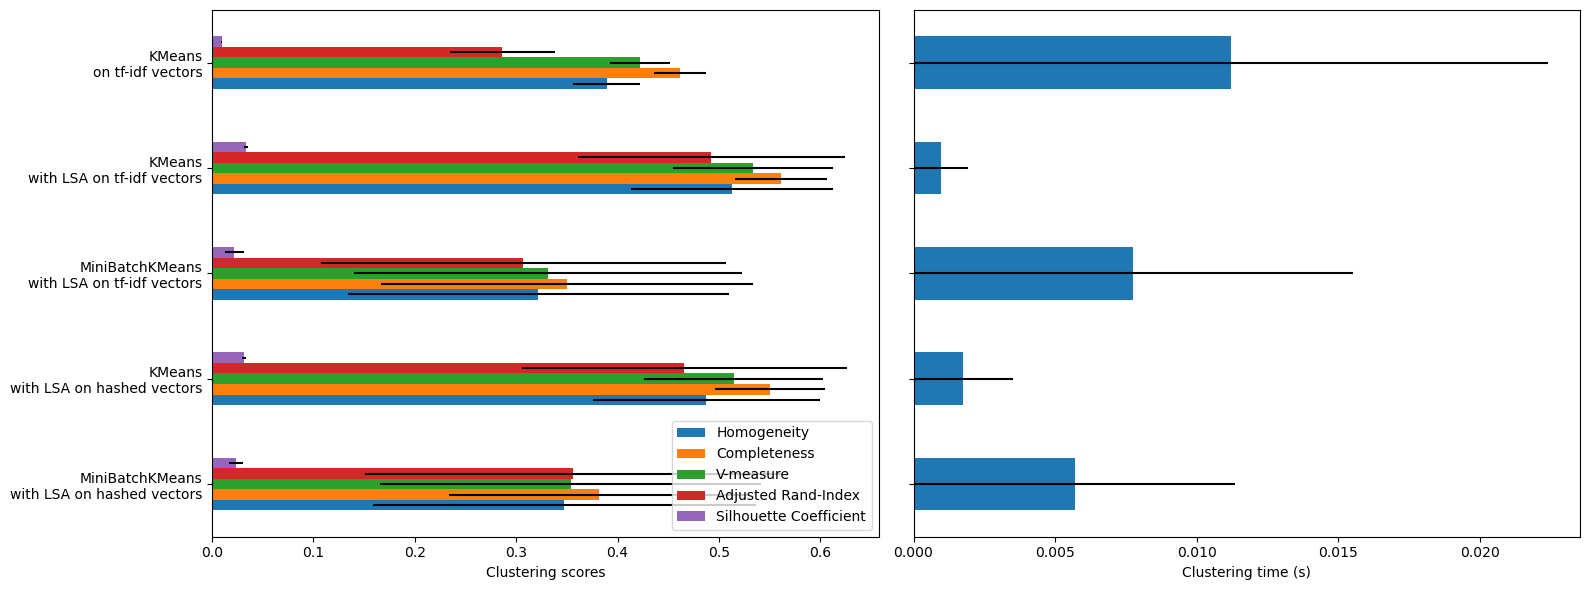

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax0, ax1) = plt.subplots(ncols=2, figsize=(16, 6), sharey=True)

df = pd.DataFrame(evaluations[::-1]).set_index("estimator")
df_std = pd.DataFrame(evaluations_std[::-1]).set_index("estimator")

df.drop(
    ["train_time"],
    axis="columns",
).plot.barh(ax=ax0, xerr=df_std)
ax0.set_xlabel("Clustering scores")
ax0.set_ylabel("")

df["train_time"].plot.barh(ax=ax1, xerr=df_std["train_time"])
ax1.set_xlabel("Clustering time (s)")
plt.tight_layout()